# XRD — radial $I(|Q|)$, Pseudo-Voigt fits, $Q_0$ & $\xi$ vs $T$

Clean notebook based on the Pseudo-Voigt workflow in the previous `xrd_final.ipynb`:

- Radial $|Q|$ integration for HT-tetragonal (scan 65) + all BM-cubic temperatures
- Pseudo-Voigt peak fits (2 peaks for 65; 1 peak for cubic)
- Profiles: **data = circles**, **fit = solid line**, same color; normalized to the fit and vertically offset
- Colors match `results_compile` (`color_list` for BM-cubic, `#ce4b5b` for scan 65)
- $Q_0(T)$ and $\xi(T)$ from Scherrer analysis


In [1]:
import sys
from pathlib import Path
import json

sys.path.append("../src/")
from xpcs import *  # noqa: F401,F403 — numpy, h5py, matplotlib, …

from lmfit.models import PseudoVoigtModel, ConstantModel
from matplotlib.lines import Line2D
import matplotlib as mpl

%matplotlib widget

# --- publication style ---
mm = 1 / 25.4


plt.rcParams['font.sans-serif'] = ['Helvetica']


legend_ax_font = 7
ax_label_font = 7
line_width = 1.0
minor_tick_length = 2.5
major_tick_length = 4
minor_tick_width = 0.5
major_tick_width = 0.75
fig_size = (100 * mm, 65 * mm)
ms = 4


# BM-cubic order / colors match results_compile
CUBIC_SCANS = ["219", "334", "552", "579", "709", "779", "796", "868"]
COLOR_CUBIC = np.array(
    ["#074a54", "#1c94b0", "#6abce7", "#9c86e3", "#ee8bb6", "#f27086", "#da499d", "#7e8285"]
)
COLOR_65 = "#ce4b5b"
TET_SCAN = "65"

SCANS = [TET_SCAN] + CUBIC_SCANS
scan_color = {s: COLOR_CUBIC[i] for i, s in enumerate(CUBIC_SCANS)}
scan_color[TET_SCAN] = COLOR_65

print("scans:", SCANS)


scans: ['65', '219', '334', '552', '579', '709', '779', '796', '868']


In [ ]:
CONFIG_FILE = Path("../configs/config_NPS_example.json")
with open(CONFIG_FILE) as f:
    config = json.load(f)
BASE_DIR = Path(config["Base"])
figure_path = CONFIG_FILE.parent.parent / config.get("Figures")
figure_path.mkdir(parents=True, exist_ok=True)

data = {}
for s in SCANS:
    proc_path = (
        BASE_DIR
        / Path(config[s])
        / Path(config["Processed"])
        / Path(config[f"{s}_processed"])
    )
    T = float(config[f"{s}_temperature"])
    if not proc_path.exists():
        print(f"Scan {s} ({T:.0f} K): missing {proc_path}")
        continue

    with h5py.File(proc_path, "r") as DATA:
        det = DATA["data/det"][:]
        Qx = DATA["pre_processing/Qx"][:]
        Qy = DATA["pre_processing/Qy"][:]

    det[det > 1000] = 0
    I_sum = np.sum(det, axis=0)
    Q_mag = np.sqrt(Qx**2 + Qy**2)

    data[s] = {
        "T": T,
        "I_sum": I_sum,
        "Qx": Qx,
        "Qy": Qy,
        "Q_mag": Q_mag,
        "nFrames": det.shape[0],
    }
    print(
        f"Scan {s:>4s} | {T:5.0f} K | {det.shape[0]} frames | "
        f"Q∈[{Q_mag.min():.4f}, {Q_mag.max():.4f}] Å⁻¹"
    )

print(f"\nLoaded {len(data)} / {len(SCANS)} scans")


Scan   65 |   298 K | 600 frames | Q∈[2.1496, 2.2559] Å⁻¹
Scan  219 |   298 K | 900 frames | Q∈[2.1448, 2.2531] Å⁻¹
Scan  334 |   305 K | 900 frames | Q∈[2.1457, 2.2526] Å⁻¹
Scan  552 |   325 K | 900 frames | Q∈[2.1459, 2.2527] Å⁻¹
Scan  579 |   345 K | 900 frames | Q∈[2.1425, 2.2511] Å⁻¹
Scan  709 |   365 K | 900 frames | Q∈[2.1445, 2.2515] Å⁻¹
Scan  779 |   385 K | 900 frames | Q∈[2.1443, 2.2507] Å⁻¹
Scan  796 |   405 K | 900 frames | Q∈[2.1426, 2.2491] Å⁻¹
Scan  868 |   350 K | 1350 frames | Q∈[2.1470, 2.2557] Å⁻¹

Loaded 9 / 9 scans


## Radial $|Q|$ integration

In [3]:
nBins_Q = 200

global_Qmin = min(data[s]["Q_mag"].min() for s in data)
global_Qmax = max(data[s]["Q_mag"].max() for s in data)
Q_edges = np.linspace(global_Qmin, global_Qmax, nBins_Q + 1)
Q_centers = 0.5 * (Q_edges[:-1] + Q_edges[1:])

radial = {}
for s in data:
    d = data[s]
    Q_flat = d["Q_mag"].ravel()
    I_flat = (d["I_sum"] / d["nFrames"]).ravel()

    I_Q = np.zeros(nBins_Q)
    counts = np.zeros(nBins_Q)
    bin_idx = np.clip(np.digitize(Q_flat, Q_edges) - 1, 0, nBins_Q - 1)
    np.add.at(I_Q, bin_idx, I_flat)
    np.add.at(counts, bin_idx, 1)

    valid = counts > 0
    I_Q[valid] /= counts[valid]
    I_norm = np.zeros_like(I_Q)
    I_norm[valid] = I_Q[valid] / I_Q[valid].max()

    # Same edge trim as original notebook
    Qv = Q_centers[valid][30:-40]
    Iv = I_norm[valid][30:-40] - I_norm[valid][0]
    radial[s] = {"Q": Qv, "I": Iv, "T": d["T"]}

print(f"Radial profiles: {list(radial)}")


Radial profiles: ['65', '219', '334', '552', '579', '709', '779', '796', '868']


## Pseudo-Voigt fits

In [4]:
def get_fit_xy(scan):
    """Scan-specific Q/I trimming (same spirit as original)."""
    Qv = radial[scan]["Q"].copy()
    Iv = radial[scan]["I"].copy()
    if scan == "65":
        Qv, Iv = Qv[:-5], Iv[:-5]
    elif scan == "868":
        Qv, Iv = Qv[5:-5], Iv[5:-5]
    elif scan == "219":
        Qv, Iv = Qv[8:], Iv[8:]
    else:
        Qv, Iv = Qv[5:-5], Iv[5:-5]
    return Qv, Iv


def build_pv_model(centers, Q, I, amplitudes=None, sigmas=None, fractions=None):
    model = None
    for k, cen in enumerate(centers):
        pv = PseudoVoigtModel(prefix=f"pv{k}_")
        model = pv if model is None else model + pv
    model = model + ConstantModel(prefix="bg_")

    params = model.make_params()
    n = len(centers)
    if amplitudes is None:
        amplitudes = [float(I.max()) / n] * n
    if sigmas is None:
        sigmas = [0.008] * n
    if fractions is None:
        fractions = [0.5] * n

    qmin, qmax = float(Q.min()), float(Q.max())
    for k, cen in enumerate(centers):
        params[f"pv{k}_center"].set(value=float(cen), min=qmin, max=qmax)
        params[f"pv{k}_amplitude"].set(value=float(amplitudes[k]), min=0, max=5 * float(I.max()))
        params[f"pv{k}_sigma"].set(value=float(sigmas[k]), min=0.001, max=0.05)
        params[f"pv{k}_fraction"].set(value=float(fractions[k]), min=0.0, max=1.0)
    params["bg_c"].set(value=float(np.min(I)), min=-0.1, max=0.15)
    return model, params


def amp_near(Q, I, mu):
    return float(I[np.argmin(np.abs(Q - mu))])


def fit_scan_pv(scan, centers, **kwargs):
    Qv, Iv = get_fit_xy(scan)
    model, params = build_pv_model(centers, Qv, Iv, **kwargs)
    result = model.fit(Iv, params, x=Qv)
    Qfine = np.linspace(Qv.min(), Qv.max(), 500)
    return Qv, Iv, Qfine, result


def scherrer_xi(fwhm, fwhm_err=None):
    """xi = 2 π K / FWHM (nm), K = 0.9."""
    K = 0.9
    xi_nm = 2 * np.pi * K / fwhm * 0.1
    if fwhm_err is None:
        return xi_nm, None
    xi_err_nm = abs(2 * np.pi * K / fwhm**2 * fwhm_err) * 0.1
    return xi_nm, xi_err_nm


def print_peak_summary(scan, result):
    npeak = sum(1 for k in result.params if k.endswith("_center"))
    print(f"\n--- Scan {scan} ({npeak} peak{'s' if npeak > 1 else ''}) ---")
    for k in range(npeak):
        p = result.params
        fwhm = p[f"pv{k}_fwhm"].value
        fwhm_err = p[f"pv{k}_fwhm"].stderr
        xi, xi_err = scherrer_xi(fwhm, fwhm_err)
        fwhm_str = f"{fwhm:.5f}" if fwhm_err is None else f"{fwhm:.5f} +/- {fwhm_err:.5f}"
        xi_str = f"{xi:.1f}" if xi_err is None else f"{xi:.1f} +/- {xi_err:.1f}"
        print(
            f"  Peak {k}: Q0 = {p[f'pv{k}_center'].value:.5f} Å⁻¹, "
            f"FWHM = {fwhm_str} Å⁻¹, η = {p[f'pv{k}_fraction'].value:.3f}, "
            f"ξ = {xi_str} nm"
        )


pv_results = {}  # scan -> dict(Q, I, Qfine, result)

# Tetragonal (65): two peaks — seeds from prior Gaussian positions
MU65_LO, MU65_HI = 2.178, 2.202
Q65, I65 = get_fit_xy("65")
Q65, I65, Qf65, res65 = fit_scan_pv(
    "65",
    centers=[MU65_LO, MU65_HI],
    amplitudes=[amp_near(Q65, I65, MU65_LO), amp_near(Q65, I65, MU65_HI)],
    sigmas=[0.004, 0.004],
)
pv_results["65"] = dict(Q=Q65, I=I65, Qfine=Qf65, result=res65)
print_peak_summary("65", res65)

# Cubic scans: single peak, seed from intensity maximum (219 seeds later scans)
mu_seed_219 = None
sig_seed_219 = None
for s in CUBIC_SCANS:
    Qv, Iv = get_fit_xy(s)
    mu0 = float(Qv[np.argmax(Iv)])
    if s == "219":
        centers = [mu0]
        amps = [float(Iv.max())]
        sigs = [0.012]
    elif mu_seed_219 is not None:
        centers = [mu_seed_219]
        amps = [float(Iv.max())]
        sigs = [sig_seed_219]
    else:
        centers = [mu0]
        amps = [float(Iv.max())]
        sigs = [0.012]

    Qv, Iv, Qfine, result = fit_scan_pv(s, centers=centers, amplitudes=amps, sigmas=sigs)
    pv_results[s] = dict(Q=Qv, I=Iv, Qfine=Qfine, result=result)
    print_peak_summary(s, result)

    if s == "219":
        mu_seed_219 = float(result.params["pv0_center"].value)
        sig_seed_219 = float(result.params["pv0_sigma"].value)



--- Scan 65 (2 peaks) ---
  Peak 0: Q0 = 2.17891 Å⁻¹, FWHM = 0.00632 +/- 0.00127 Å⁻¹, η = 0.830, ξ = 89.5 +/- 18.0 nm
  Peak 1: Q0 = 2.20198 Å⁻¹, FWHM = 0.00236 +/- 0.00002 Å⁻¹, η = 0.516, ξ = 239.6 +/- 2.1 nm

--- Scan 219 (1 peak) ---
  Peak 0: Q0 = 2.19801 Å⁻¹, FWHM = 0.01656 +/- 0.00025 Å⁻¹, η = 0.703, ξ = 34.2 +/- 0.5 nm

--- Scan 334 (1 peak) ---
  Peak 0: Q0 = 2.19819 Å⁻¹, FWHM = 0.01230 +/- 0.00015 Å⁻¹, η = 0.911, ξ = 46.0 +/- 0.5 nm

--- Scan 552 (1 peak) ---
  Peak 0: Q0 = 2.19840 Å⁻¹, FWHM = 0.01137 +/- 0.00014 Å⁻¹, η = 0.794, ξ = 49.7 +/- 0.6 nm

--- Scan 579 (1 peak) ---
  Peak 0: Q0 = 2.19594 Å⁻¹, FWHM = 0.01637 +/- 0.00025 Å⁻¹, η = 0.732, ξ = 34.6 +/- 0.5 nm

--- Scan 709 (1 peak) ---
  Peak 0: Q0 = 2.19711 Å⁻¹, FWHM = 0.00902 +/- 0.00016 Å⁻¹, η = 0.733, ξ = 62.7 +/- 1.1 nm

--- Scan 779 (1 peak) ---
  Peak 0: Q0 = 2.19813 Å⁻¹, FWHM = 0.01916 +/- 0.00057 Å⁻¹, η = 0.858, ξ = 29.5 +/- 0.9 nm

--- Scan 796 (1 peak) ---
  Peak 0: Q0 = 2.19603 Å⁻¹, FWHM = 0.01914 +/- 0.00042

## Normalized + offset $I(|Q|)$

Data = circles, fit = solid line (same color). Intensities are background-subtracted and scaled by the fit peak height, then offset by temperature.


Common Q window: [2.16661, 2.22332] Å⁻¹
wrote ../figures/radial_iq_pseudo_voigt_allT.pdf


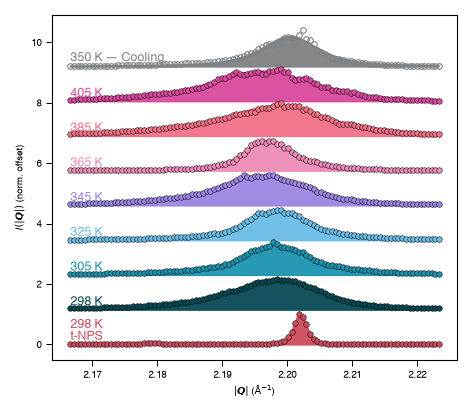

In [5]:
OFFSET = 1.15  # vertical spacing between normalized profiles

# Common |Q| window for all temperatures:
#   Q_lo = min(Qmin of scan 65, Qmin of scan 219)
#   Q_hi = Qmax of 405 K (scan 796)
Q_lo = min(pv_results["65"]["Q"].min(), pv_results["219"]["Q"].min())
Q_hi = pv_results["796"]["Q"].max()
print(f"Common Q window: [{Q_lo:.5f}, {Q_hi:.5f}] Å⁻¹")

# Stack order: tetragonal at bottom, then cubic in results_compile order
plot_order = [s for s in SCANS if s in pv_results]

fig, ax = plt.subplots(figsize=(fig_size[0] + 20 * mm, fig_size[1] + 40 * mm))

for i, scan in enumerate(plot_order):
    d = data[scan]
    col = scan_color[scan]
    rec = pv_results[scan]
    Qv, Iv, Qfine, result = rec["Q"], rec["I"], rec["Qfine"], rec["result"]

    bg = result.params["bg_c"].value
    fit_raw = result.eval(x=Qfine)
    amp = float(np.max(fit_raw - bg))
    Iv_n = (Iv - bg) / amp
    fit_n = (fit_raw - bg) / amp

    # Truncate every scan to the common Q window
    m_data = (Qv >= Q_lo) & (Qv <= Q_hi)
    m_fit = (Qfine >= Q_lo) & (Qfine <= Q_hi)
    Qv, Iv_n = Qv[m_data], Iv_n[m_data]
    Qfine, fit_n = Qfine[m_fit], fit_n[m_fit]

    y0 = i * OFFSET

    if scan == "868":
        label = f"{d['T']:.0f} K — Cooling"
        ax.plot(
            Qv, Iv_n + y0, "o", ms=ms,
            markerfacecolor="none", markeredgecolor=col, markeredgewidth=0.8,
            zorder=10 + i,
        )
    else:
        label = f"{d['T']:.0f} K\nt-NPS" if scan == "65" else f"{d['T']:.0f} K"
        ax.plot(
            Qv, Iv_n + y0, "o", ms=ms, color=col,
            markeredgecolor="black", markeredgewidth=0.35,
            zorder=10 + i,
        )

    ax.fill_between(Qfine, y0, fit_n + y0, color=col, alpha=0.95, zorder=5 + i)
    ax.plot(Qfine, fit_n + y0, "-", color=col, lw=line_width, alpha=0.95, zorder=5 + i)

    # Temperature label above the curve on the left
    ax.text(
        Q_lo,
        y0 + 0.075,
        label,
        color=col,
        fontsize=legend_ax_font+2,
        ha="left",
        va="bottom",
        zorder=20 + i,
    )

ax.set_xlabel(r"$|\boldsymbol{Q}|$ ($\mathrm{\AA}^{-1}$)", fontsize=ax_label_font)
ax.set_ylabel(r"$I(|\boldsymbol{Q}|)$ (norm. offset)", fontsize=ax_label_font)
ax.tick_params(which="major", length=major_tick_length, width=major_tick_width, labelsize=legend_ax_font)
ax.tick_params(which="minor", length=minor_tick_length, width=minor_tick_width)
fig.tight_layout()

out_iq = figure_path / "radial_iq_pseudo_voigt_allT.pdf"
fig.savefig(out_iq, format="pdf", dpi=300, bbox_inches="tight", metadata={"Creator": ""})
print(f"wrote {out_iq}")
plt.show()


## $Q_0(T)$ and $\xi(T)$

Scherrer: $\xi = 2\pi K / \mathrm{FWHM}$ with $K=0.9$ (nm). Tetragonal peaks use `#ce4b5b`; BM-cubic uses `color_list`.


wrote ../figures/peak_position_vs_temperature_allT.pdf


/var/folders/jg/p8s420v17f3064xm8v_n78s00000gn/T/ipykernel_72803/79685295.py:161: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


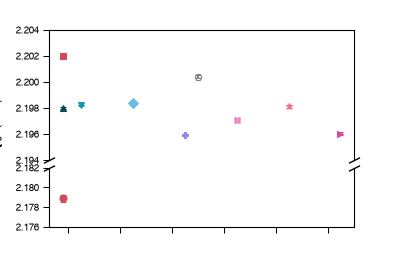

wrote ../figures/correlation_length_vs_temperature_allT.pdf


/var/folders/jg/p8s420v17f3064xm8v_n78s00000gn/T/ipykernel_72803/79685295.py:269: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


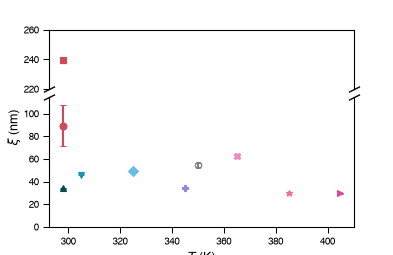


Peak summary:
  $t$-(112)                     T=298 K  |Q|=2.17891 +/- 0.00034  FWHM=0.00632 +/- 0.00127  xi=89.5 +/- 18.0 nm
  $t$-(211)                     T=298 K  |Q|=2.20198 +/- 0.00001  FWHM=0.00236 +/- 0.00002  xi=239.6 +/- 2.1 nm
  "$c$"-(211) 298 K             T=298 K  |Q|=2.19801 +/- 0.00007  FWHM=0.01656 +/- 0.00025  xi=34.2 +/- 0.5 nm
  "$c$"-(211) 305 K             T=305 K  |Q|=2.19819 +/- 0.00004  FWHM=0.01230 +/- 0.00015  xi=46.0 +/- 0.5 nm
  "$c$"-(211) 325 K             T=325 K  |Q|=2.19840 +/- 0.00004  FWHM=0.01137 +/- 0.00014  xi=49.7 +/- 0.6 nm
  "$c$"-(211) 345 K             T=345 K  |Q|=2.19594 +/- 0.00007  FWHM=0.01637 +/- 0.00025  xi=34.6 +/- 0.5 nm
  "$c$"-(211) 365 K             T=365 K  |Q|=2.19711 +/- 0.00005  FWHM=0.00902 +/- 0.00016  xi=62.7 +/- 1.1 nm
  "$c$"-(211) 385 K             T=385 K  |Q|=2.19813 +/- 0.00012  FWHM=0.01916 +/- 0.00057  xi=29.5 +/- 0.9 nm
  "$c$"-(211) 405 K             T=405 K  |Q|=2.19603 +/- 0.00011  FWHM=0.01914 +/- 0.00042  xi=

In [6]:
peak_rows = []

# Scan 65 — two tetragonal peaks
res65 = pv_results["65"]["result"]
T65 = float(data["65"]["T"])
for k, (peak_id, mkr, label) in enumerate(
    (("112", "o", r"$t$-(112)"), ("211", "s", r"$t$-(211)"))
):
    p = res65.params
    fwhm = p[f"pv{k}_fwhm"].value
    fwhm_err = p[f"pv{k}_fwhm"].stderr
    xi, xi_err = scherrer_xi(fwhm, fwhm_err)
    peak_rows.append(
        dict(
            peak_id=peak_id,
            label=label,
            scan="65",
            T=T65,
            Q=p[f"pv{k}_center"].value,
            Q_err=p[f"pv{k}_center"].stderr,
            fwhm=fwhm,
            fwhm_err=fwhm_err,
            xi=xi,
            xi_err=xi_err,
            color=COLOR_65,
            marker=mkr,
        )
    )

# BM-cubic — single (211)-like peak
markers_cubic = ["^", "v", "D", "P", "X", "*", ">", "H"]
for i, scan in enumerate(CUBIC_SCANS):
    if scan not in pv_results:
        continue
    res = pv_results[scan]["result"]
    p = res.params
    fwhm = p["pv0_fwhm"].value
    fwhm_err = p["pv0_fwhm"].stderr
    xi, xi_err = scherrer_xi(fwhm, fwhm_err)
    T = float(data[scan]["T"])
    label = f'"$c$"-(211) {T:.0f} K' + (" cool" if scan == "868" else "")
    peak_rows.append(
        dict(
            peak_id="211",
            label=label,
            scan=scan,
            T=T,
            Q=p["pv0_center"].value,
            Q_err=p["pv0_center"].stderr,
            fwhm=fwhm,
            fwhm_err=fwhm_err,
            xi=xi,
            xi_err=xi_err,
            color=scan_color[scan],
            marker=markers_cubic[i],
        )
    )


def plot_vs_T(rows, y_key, y_err_key, ylabel, pdf_name, ylim=None, show_112=True):
    use = rows if show_112 else [r for r in rows if r["peak_id"] != "112"]
    fig, ax = plt.subplots(figsize=fig_size)

    for row in use:
        yerr = row[y_err_key] if row[y_err_key] is not None else 0.0
        mfc = "none" if row["scan"] == "868" else row["color"]
        ax.errorbar(
            row["T"],
            row[y_key],
            yerr=yerr,
            fmt=row["marker"],
            ms=ms + 1,
            color=row["color"],
            ecolor=row["color"],
            markerfacecolor=mfc,
            markeredgecolor=row["color"],
            markeredgewidth=0.8,
            capsize=2,
            linestyle="none",
            label=row["label"],
        )

    ax.set_xlabel(r"$T$ (K)", fontsize=ax_label_font)
    ax.set_ylabel(ylabel, fontsize=ax_label_font)
    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.tick_params(which="major", length=major_tick_length, width=major_tick_width, labelsize=legend_ax_font)
    ax.tick_params(which="minor", length=minor_tick_length, width=minor_tick_width)
    ax.legend(fontsize=legend_ax_font - 1.5, frameon=False, loc="best")
    fig.tight_layout()

    out = figure_path / pdf_name
    fig.savefig(out, format="pdf", dpi=300, bbox_inches="tight", metadata={"Creator": ""})
    print(f"wrote {out}")
    plt.show()
    return fig


SHOW_PEAK_112 = True

def plot_q_vs_T_broken(
    rows,
    pdf_name="peak_position_vs_temperature_allT.pdf",
    show_112=True,
    ylim_lo=(2.176, 2.182),
    ylim_hi=(2.194, 2.204),
):
    """Q0 vs T with a broken y-axis separating t-(112) from the main cluster."""
    use = rows if show_112 else [r for r in rows if r["peak_id"] != "112"]

    fig, (ax_hi, ax_lo) = plt.subplots(
        2, 1, sharex=True, figsize=fig_size,
        gridspec_kw={"height_ratios": [2.2, 1], "hspace": 0.08},
    )

    for ax in (ax_hi, ax_lo):
        for row in use:
            yerr = row["Q_err"] if row["Q_err"] is not None else 0.0
            mfc = "none" if row["scan"] == "868" else row["color"]
            ax.errorbar(
                row["T"], row["Q"], yerr=yerr,
                fmt=row["marker"], ms=ms + 1,
                color=row["color"], ecolor=row["color"],
                markerfacecolor=mfc, markeredgecolor=row["color"],
                markeredgewidth=0.8, capsize=2, linestyle="none",
            )

    ax_hi.set_ylim(*ylim_hi)
    ax_lo.set_ylim(*ylim_lo)
    ax_hi.spines["bottom"].set_visible(False)
    ax_lo.spines["top"].set_visible(False)
    ax_hi.tick_params(axis="x", which="both", bottom=False, labelbottom=False)
    ax_lo.xaxis.tick_bottom()

    d = 0.5
    kwargs = dict(
        marker=[(-1, -d), (1, d)], markersize=8,
        linestyle="none", color="k", mec="k", mew=1, clip_on=False,
    )
    ax_hi.plot([0], [0], transform=ax_hi.transAxes, **kwargs)
    ax_hi.plot([1], [0], transform=ax_hi.transAxes, **kwargs)
    ax_lo.plot([0], [1], transform=ax_lo.transAxes, **kwargs)
    ax_lo.plot([1], [1], transform=ax_lo.transAxes, **kwargs)

    fig.supylabel(
        r"|$\boldsymbol{Q}_0$| ($\mathrm{\AA}^{-1}$)",
        fontsize=ax_label_font + 2,
        x=-0.03,
    )
    for ax in (ax_hi, ax_lo):
        ax.tick_params(
            which="major", length=major_tick_length,
            width=major_tick_width, labelsize=legend_ax_font,
        )
        ax.tick_params(
            which="minor", length=minor_tick_length, width=minor_tick_width,
        )
        ax.tick_params(axis="x", which="both", labelbottom=False)
    ax_lo.xaxis.offsetText.set_visible(False)

    fig.tight_layout()
    out = figure_path / pdf_name
    fig.savefig(out, format="pdf", dpi=300, bbox_inches="tight", metadata={"Creator": ""})
    print(f"wrote {out}")
    plt.show()
   


plot_q_vs_T_broken(
    peak_rows,
    pdf_name="peak_position_vs_temperature_allT.pdf",
    show_112=SHOW_PEAK_112,
    ylim_lo=(2.176, 2.182),
    ylim_hi=(2.194, 2.204),
)

def plot_xi_vs_T_broken(
    rows,
    pdf_name="correlation_length_vs_temperature_allT.pdf",
    show_112=False,
    ylim_lo=(0, 115),
    ylim_hi=(220, 260),
):
    """ξ vs T with a broken y-axis so the ~250 nm tetragonal point fits."""
    use = rows if show_112 else [r for r in rows if r["peak_id"] != "112"]

    fig, (ax_hi, ax_lo) = plt.subplots(
        2, 1, sharex=True, figsize=fig_size,
        gridspec_kw={"height_ratios": [1, 2.2], "hspace": 0.08},
    )

    for ax in (ax_hi, ax_lo):
        for row in use:
            yerr = row["xi_err"] if row["xi_err"] is not None else 0.0
            mfc = "none" if row["scan"] == "868" else row["color"]
            ax.errorbar(
                row["T"],
                row["xi"],
                yerr=yerr,
                fmt=row["marker"],
                ms=ms + 1,
                color=row["color"],
                ecolor=row["color"],
                markerfacecolor=mfc,
                markeredgecolor=row["color"],
                markeredgewidth=0.8,
                capsize=2,
                linestyle="none",
                label=row["label"],
            )

    ax_hi.set_ylim(*ylim_hi)
    ax_lo.set_ylim(*ylim_lo)

    # Hide spines at the break; no shared tick clutter
    ax_hi.spines["bottom"].set_visible(False)
    ax_lo.spines["top"].set_visible(False)
    ax_hi.tick_params(axis="x", which="both", bottom=False, labelbottom=False)
    ax_lo.xaxis.tick_bottom()

    # 45° break marks on both sides of the gap
    d = 0.5
    kwargs = dict(
        marker=[(-1, -d), (1, d)],
        markersize=8,
        linestyle="none",
        color="k",
        mec="k",
        mew=1,
        clip_on=False,
    )
    ax_hi.plot([0], [0], transform=ax_hi.transAxes, **kwargs)
    ax_hi.plot([1], [0], transform=ax_hi.transAxes, **kwargs)
    ax_lo.plot([0], [1], transform=ax_lo.transAxes, **kwargs)
    ax_lo.plot([1], [1], transform=ax_lo.transAxes, **kwargs)

    ax_lo.set_xlabel(r"$T$ (K)", fontsize=ax_label_font+2)
    fig.supylabel(r"$\xi$ (nm)", fontsize=ax_label_font+2)
    for ax in (ax_hi, ax_lo):
        ax.tick_params(
            which="major",
            length=major_tick_length,
            width=major_tick_width,
            labelsize=legend_ax_font,
        )
        ax.tick_params(
            which="minor",
            length=minor_tick_length,
            width=minor_tick_width,
        )

    # Legend once, on the lower panel (cubic cluster)
    handles, labels = ax_lo.get_legend_handles_labels()
    # de-duplicate (same labels plotted on both axes)
    seen = set()
    uniq = []
    for h, lab in zip(handles, labels):
        if lab not in seen:
            seen.add(lab)
            uniq.append((h, lab))
    #ax_lo.legend(
    #    [h for h, _ in uniq],
    #    [lab for _, lab in uniq],
    #    fontsize=legend_ax_font - 1.5,
    #    frameon=False,
    #    loc="best",
    #)

    fig.tight_layout()
    out = figure_path / pdf_name
    fig.savefig(out, format="pdf", dpi=300, bbox_inches="tight", metadata={"Creator": ""})
    print(f"wrote {out}")
    plt.show()
    return fig


plot_xi_vs_T_broken(
    peak_rows,
    pdf_name="correlation_length_vs_temperature_allT.pdf",
    show_112=SHOW_PEAK_112,
    ylim_lo=(0, 115),
    ylim_hi=(220, 260),
)

print("\nPeak summary:")
for row in peak_rows:
    qe, fe, xe = row["Q_err"], row["fwhm_err"], row["xi_err"]
    qs = f"{row['Q']:.5f}" if qe is None else f"{row['Q']:.5f} +/- {qe:.5f}"
    fs = f"{row['fwhm']:.5f}" if fe is None else f"{row['fwhm']:.5f} +/- {fe:.5f}"
    xs = f"{row['xi']:.1f}" if xe is None else f"{row['xi']:.1f} +/- {xe:.1f}"
    print(f"  {row['label']:28s}  T={row['T']:.0f} K  |Q|={qs}  FWHM={fs}  xi={xs} nm")


## Publication panel — scans 65, 219, 868

Same three-scan figure as the original `xrd_final` Pseudo-Voigt cell: overlaid normalized $I(|Q|)$ (data = circles, fit = solid fill) plus broken-axis $Q_0(T)$ and $\xi(T)$.


Publication overlay Q_hi = 2.23012 Å⁻¹
wrote ../figures/radial_iq_pseudo_voigt.pdf


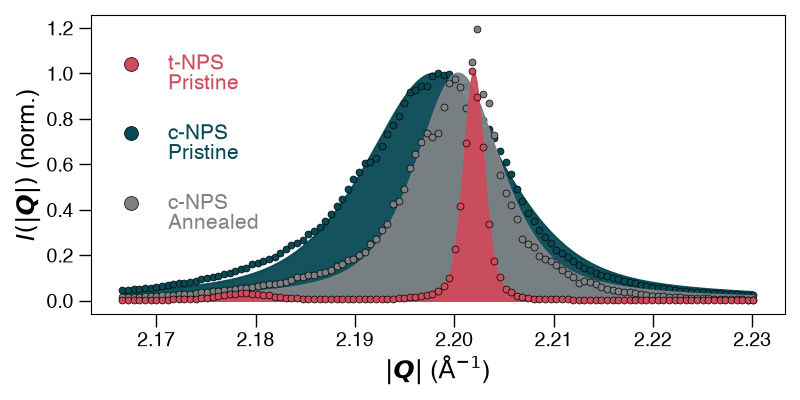

peak_position_vs_temperature.pdf: xlim=(np.float64(273.0), np.float64(375.0)), ylim=(np.float64(2.19594285924984), np.float64(2.203987415324029))


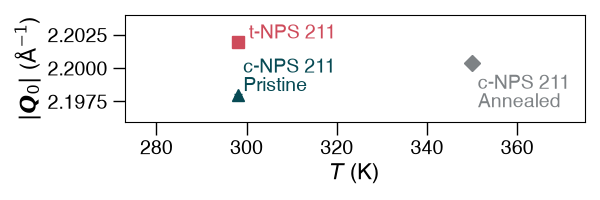

wrote ../figures/peak_position_vs_temperature.pdf


/var/folders/jg/p8s420v17f3064xm8v_n78s00000gn/T/ipykernel_72803/164930137.py:312: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


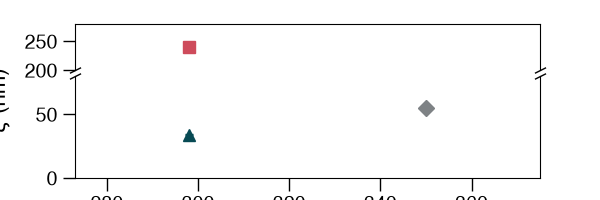

wrote ../figures/correlation_length_vs_temperature.pdf

Publication peak summary (65, 219, 868):
  t-NPS 112             T=298 K  |Q|=2.17891 +/- 0.00034  FWHM=0.00632 +/- 0.00127  xi=89.5 +/- 18.0 nm
  t-NPS 211             T=298 K  |Q|=2.20198 +/- 0.00001  FWHM=0.00236 +/- 0.00002  xi=239.6 +/- 2.1 nm
  c-NPS 211
Pristine    T=298 K  |Q|=2.19801 +/- 0.00007  FWHM=0.01656 +/- 0.00025  xi=34.2 +/- 0.5 nm
  c-NPS 211
Annealed    T=350 K  |Q|=2.20040 +/- 0.00009  FWHM=0.01033 +/- 0.00034  xi=54.7 +/- 1.8 nm


In [7]:
plt.rcParams['font.sans-serif'] = ['Helvetica']

legend_ax_font = 12
ax_label_font = 16
ax_title_font = 18
line_width = 2.5

minor_tick_length = 6
major_tick_length = 9
minor_tick_width = 0.75
major_tick_width = 1.0

fig_size = (8,5)

ms = 8


# --- 3-scan publication subset (original cell layout) ---
PUB_SCANS = ["65", "219", "868"]
PUB_COLORS = np.array(["#ce4b5b", "#074a54", "#7e8285"])
PUB_LABELS = [
    "\n(HT)-$t$-Na$_{3}$PS$_{4}$\nPristine",
    '\n(BM)-"$c$"-Na$_{3}$PS$_{4}$\nPristine',
    '\n(BM)-"$c$"-Na$_{3}$PS$_{4}$\nAnnealed',
]


PUB_LABELS = [
    "\nt-NPS\nPristine",
    '\nc-NPS\nPristine',
    '\nc-NPS\nAnnealed',
]
# --- Overlaid I(|Q|): normalized to fit peak, no vertical offset ---
# Cap high-Q at the shorter of scans 65 and 868 so 219 does not overhang
Q_hi_pub = min(pv_results["65"]["Q"].max(), pv_results["868"]["Q"].max())
print(f"Publication overlay Q_hi = {Q_hi_pub:.5f} Å⁻¹")

fig_pv, ax_pv = plt.subplots(figsize=(fig_size[0], fig_size[1]*0.8))

for idx, scan in enumerate(PUB_SCANS):
    rec = pv_results[scan]
    Qv, Iv, Qfine, result = rec["Q"], rec["I"], rec["Qfine"], rec["result"]
    col = PUB_COLORS[idx]
    d = data[scan]

    if scan == "65":
        z = 4
    elif scan == "219":
        z = 0
    else:
        z = 2

    bg = result.params["bg_c"].value
    fit_raw = result.eval(x=Qfine)
    amp = float(np.max(fit_raw - bg))
    Iv_n = (Iv - bg) / amp
    fit_n = (fit_raw - bg) / amp

    m_data = Qv <= Q_hi_pub
    m_fit = Qfine <= Q_hi_pub
    Qv, Iv_n = Qv[m_data], Iv_n[m_data]
    Qfine, fit_n = Qfine[m_fit], fit_n[m_fit]

    ax_pv.plot(
        Qv, Iv_n, ".", ms=ms + 2, color=col,
        markeredgecolor="black", markeredgewidth=0.5,
        label=PUB_LABELS[idx], zorder=z + 1,
    )
    ax_pv.fill_between(Qfine, 0, fit_n, color=col, alpha=0.95, zorder=z)
    ax_pv.plot(Qfine, fit_n, "-", color=col, lw=line_width / 2, alpha=0.95, zorder=z)

ax_pv.set_xlabel(r"$|\boldsymbol{Q}|$ ($\mathrm{\AA}^{-1}$)", fontsize=ax_label_font + 2)
ax_pv.set_ylabel(r"$I(|\boldsymbol{Q}|)$ (norm.)", fontsize=ax_label_font + 2)
#ax_pv.legend(fontsize=legend_ax_font + 3, markerscale=3, loc="upper left", frameon=False)

leg = ax_pv.legend(fontsize=legend_ax_font + 3, markerscale=2, loc="upper left", frameon=False)
for text, handle in zip(leg.get_texts(), leg.legend_handles):
    text.set_color(handle.get_markerfacecolor())

ax_pv.tick_params(
    which="major", length=major_tick_length, width=major_tick_width, labelsize=legend_ax_font+2,
)
fig_pv.tight_layout()
fig_pv.savefig(
    figure_path / "radial_iq_pseudo_voigt.pdf",
    format="pdf", dpi=300, bbox_inches="tight", metadata={"Creator": ""},
)
print(f"wrote {figure_path / 'radial_iq_pseudo_voigt.pdf'}")
plt.show()


# --- Peak rows for broken-axis Q0 / xi plots ---
pub_peak_rows = []

res65 = pv_results["65"]["result"]
T65 = float(data["65"]["T"])
for k, (peak_id, mkr, label, xytext, ha, va) in enumerate(
    (
        ("112", "o", r"t-NPS 112", (8, 12), "left", "top"),
        ("211", "s", r"t-NPS 211", (8, 0), "left", "bottom"),
    )
):
    p = res65.params
    fwhm = p[f"pv{k}_fwhm"].value
    fwhm_err = p[f"pv{k}_fwhm"].stderr
    xi, xi_err = scherrer_xi(fwhm, fwhm_err)
    pub_peak_rows.append(
        dict(
            peak_id=peak_id,
            label=label,
            scan="65",
            T=T65,
            Q=p[f"pv{k}_center"].value,
            Q_err=p[f"pv{k}_center"].stderr,
            fwhm=fwhm,
            fwhm_err=fwhm_err,
            xi=xi,
            xi_err=xi_err,
            color=PUB_COLORS[0],
            marker=mkr,
            label_xytext=xytext,
            label_ha=ha,
            label_va=va,
        )
    )

for scan, idx, mkr, label, xytext, ha, va in (
    ("219", 1, "^", 'c-NPS 211\nPristine', (4, 0), "left", "bottom"),
    ("868", 2, "D", 'c-NPS 211\nAnnealed', (4, -8), "left", "top"),
):
    res = pv_results[scan]["result"]
    p = res.params
    fwhm = p["pv0_fwhm"].value
    fwhm_err = p["pv0_fwhm"].stderr
    xi, xi_err = scherrer_xi(fwhm, fwhm_err)
    pub_peak_rows.append(
        dict(
            peak_id="211",
            label=label,
            scan=scan,
            T=float(data[scan]["T"]),
            Q=p["pv0_center"].value,
            Q_err=p["pv0_center"].stderr,
            fwhm=fwhm,
            fwhm_err=fwhm_err,
            xi=xi,
            xi_err=xi_err,
            color=PUB_COLORS[idx],
            marker=mkr,
            label_xytext=xytext,
            label_ha=ha,
            label_va=va,
        )
    )


def plot_pub_vs_T(
    rows,
    y_key,
    y_err_key,
    ylabel,
    pdf_name,
    annotate_markers=False,
    show_peak_112=False,
    ylim=None,
):
    """Single continuous T-axis plot for the 65 / 219 / 868 subset."""
    use = rows if show_peak_112 else [r for r in rows if r.get("peak_id") != "112"]

    fig, ax = plt.subplots(figsize=PUB_FIGSIZE)

    for row in use:
        yerr = row[y_err_key] if row[y_err_key] is not None else 0.0
        ax.errorbar(
            row["T"], row[y_key], yerr=yerr,
            fmt=row["marker"], ms=ms,
            color=row["color"], ecolor=row["color"],
            capsize=3, linestyle="none",
        )
        if annotate_markers:
            dx, dy = row.get("label_xytext", (6, 4))
            ax.annotate(
                row["label"], (row["T"], row[y_key]),
                xytext=(dx, dy), textcoords="offset points",
                fontsize=legend_ax_font + 2, color=row["color"],
                ha=row.get("label_ha", "left"), va=row.get("label_va", "bottom"),
            )

    temps = np.array([row["T"] for row in use], dtype=float)
    # Match correlation-length figure T window
    ax.set_xlim(temps.min() - PUB_PAD_T, temps.max() + PUB_PAD_T)

    ys = np.array([row[y_key] for row in use], dtype=float)
    yerrs = np.array([
        row[y_err_key] if row[y_err_key] is not None else 0.0 for row in use
    ], dtype=float)
    y_lo = float(np.min(ys - yerrs))
    y_hi = float(np.max(ys + yerrs))
    span = max(y_hi - y_lo, 1e-6)
    # Fractional pad + floor so tiny |Q| spans still get visible margin
    pad_y = max(0.35 * span, 0.002 if y_key == "Q" else 0.05 * max(abs(y_hi), 1.0))
    y0 = y_lo - pad_y
    y1 = y_hi + pad_y
    if ylim is not None and ylim[0] is not None:
        y0 = max(y0, ylim[0])
    if ylim is not None and ylim[1] is not None:
        y1 = max(y1, ylim[1])
    ax.set_ylim(y0, y1)
    print(f"{pdf_name}: xlim={ax.get_xlim()}, ylim={ax.get_ylim()}")

    ax.set_xlabel(r"$T$ (K)", fontsize=ax_label_font)
    ax.set_ylabel(ylabel, fontsize=ax_label_font)
    ax.tick_params(
        which="major", length=major_tick_length, width=major_tick_width,
        labelsize=legend_ax_font + 2,
    )
    ax.tick_params(
        which="minor", length=minor_tick_length, width=minor_tick_width,
    )
    fig.tight_layout()
    plt.show()
    fig.savefig(figure_path / pdf_name, format="pdf", dpi=300, bbox_inches="tight", metadata={"Creator": ""})
    print(f"wrote {figure_path / pdf_name}")
    return fig


PUB_FIGSIZE = (fig_size[0] * 0.75, fig_size[1] // 2)  # shared Q0 / ξ figure size
PUB_PAD_T = 25  # shared T-axis padding (K)

SHOW_PEAK_112 = False

plot_pub_vs_T(
    pub_peak_rows,
    y_key="Q",
    y_err_key="Q_err",
    ylabel=r"$|\boldsymbol{Q}_0|$ ($\mathrm{\AA}^{-1}$)",
    pdf_name="peak_position_vs_temperature.pdf",
    annotate_markers=True,
    show_peak_112=SHOW_PEAK_112,
    ylim=None,
)

def plot_pub_xi_broken(
    rows,
    pdf_name="correlation_length_vs_temperature.pdf",
    annotate_markers=True,
    show_peak_112=False,
    ylim_lo=(0, 80),
    ylim_hi=(200, 280),
    pad_T=25,
):
    """ξ vs T with broken y-axis for the ~250 nm tetragonal point."""
    use = rows if show_peak_112 else [r for r in rows if r.get("peak_id") != "112"]

    fig, (ax_hi, ax_lo) = plt.subplots(
        2, 1, sharex=True,
        figsize=PUB_FIGSIZE,
        gridspec_kw={"height_ratios": [1, 2.2], "hspace": 0.08},
    )

    for ax in (ax_hi, ax_lo):
        for row in use:
            yerr = row["xi_err"] if row["xi_err"] is not None else 0.0
            ax.errorbar(
                row["T"], row["xi"], yerr=yerr,
                fmt=row["marker"], ms=ms,
                color=row["color"], ecolor=row["color"],
                capsize=3, linestyle="none",
            )
            if annotate_markers:
                dx, dy = row.get("label_xytext", (6, 4))
                ax.annotate(
                    row["label"], (row["T"], row["xi"]),
                    xytext=(dx, dy), textcoords="offset points",
                    fontsize=legend_ax_font + 2, color=row["color"],
                    ha=row.get("label_ha", "left"), va=row.get("label_va", "bottom"),
                    clip_on=False,
                )

    ax_hi.set_ylim(*ylim_hi)
    ax_lo.set_ylim(*ylim_lo)

    temps = np.array([row["T"] for row in use], dtype=float)
    ax_lo.set_xlim(temps.min() - PUB_PAD_T, temps.max() + PUB_PAD_T)

    ax_hi.spines["bottom"].set_visible(False)
    ax_lo.spines["top"].set_visible(False)
    ax_hi.tick_params(axis="x", which="both", bottom=False, labelbottom=False)
    ax_lo.xaxis.tick_bottom()

    d = 0.5
    kwargs = dict(
        marker=[(-1, -d), (1, d)], markersize=8,
        linestyle="none", color="k", mec="k", mew=1, clip_on=False,
    )
    ax_hi.plot([0], [0], transform=ax_hi.transAxes, **kwargs)
    ax_hi.plot([1], [0], transform=ax_hi.transAxes, **kwargs)
    ax_lo.plot([0], [1], transform=ax_lo.transAxes, **kwargs)
    ax_lo.plot([1], [1], transform=ax_lo.transAxes, **kwargs)

    ax_lo.set_xlabel(r"$T$ (K)", fontsize=ax_label_font)
    fig.supylabel(r"$\xi$ (nm)", fontsize=ax_label_font,x=-0.02)
    for ax in (ax_hi, ax_lo):
        ax.tick_params(
            which="major", length=major_tick_length, width=major_tick_width,
            labelsize=legend_ax_font + 2,
        )
        ax.tick_params(
            which="minor", length=minor_tick_length, width=minor_tick_width,
        )

    fig.tight_layout()
    plt.show()
    fig.savefig(figure_path / pdf_name, format="pdf", dpi=300, bbox_inches="tight", metadata={"Creator": ""})
    print(f"wrote {figure_path / pdf_name}")
    return fig


plot_pub_xi_broken(
    pub_peak_rows,
    pdf_name="correlation_length_vs_temperature.pdf",
    annotate_markers=False,
    show_peak_112=SHOW_PEAK_112,
    ylim_lo=(0, 80),
    ylim_hi=(200, 280),
)

print("\nPublication peak summary (65, 219, 868):")
for row in pub_peak_rows:
    qe, fe, xe = row["Q_err"], row["fwhm_err"], row["xi_err"]
    qs = f"{row['Q']:.5f}" if qe is None else f"{row['Q']:.5f} +/- {qe:.5f}"
    fs = f"{row['fwhm']:.5f}" if fe is None else f"{row['fwhm']:.5f} +/- {fe:.5f}"
    xs = f"{row['xi']:.1f}" if xe is None else f"{row['xi']:.1f} +/- {xe:.1f}"
    print(f"  {row['label']:20s}  T={row['T']:.0f} K  |Q|={qs}  FWHM={fs}  xi={xs} nm")
